# NSPPK Classifier Benchmark

Compare the `NSPPKClassifier` `linear` and `rf` shortcuts on the local MoleculeNet HIV dataset. The benchmark uses 14-bit NSPPK features (`radius=1`, `distance=4`, `connector=1`) and repeated stratified 70/30 splits.

Fit time includes graph feature generation and estimator training. Prediction and score times each include transforming the test graphs; this makes the wrapper's public `predict` and `predict_proba` costs explicit. Average precision and balanced accuracy accompany ordinary accuracy because the HIV sample is imbalanced.


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import RDLogger
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(path for path in REPO_CANDIDATES if (path / "src").exists())
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nsppk import NSPPK, NSPPKClassifier

DATASET_FILE = REPO_ROOT / "data" / "HIV.csv"
LIMIT = 8000
NBITS = 14
RADIUS = 1
DISTANCE = 4
CONNECTOR = 1
N_REPEATS = 3
RANDOM_STATE = 42
TEST_SIZE = 0.30

RDLogger.DisableLog("rdApp.*")


## Load the graph sample

The same fixed graph sample is reused for every split and estimator. With an 8,000-graph cap, `balance=True` may still return an imbalanced sample when the minority class is too small to balance all requested rows; the observed class rates are printed below.


In [2]:
loader = NSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    connector=CONNECTOR,
    nbits=NBITS,
    dense=False,
    parallel=True,
)
graphs = loader.load_from(
    DATASET_FILE,
    "smiles",
    limit=LIMIT,
    random_state=RANDOM_STATE,
    balance=True,
    label_extractor=lambda graph: int(graph.graph["HIV_active"]),
)
y = np.asarray([int(graph.graph["HIV_active"]) for graph in graphs])

print(f"Dataset: {DATASET_FILE}")
print(f"Graphs: {len(graphs):,}")
print(f"Positive rate: {y.mean():.3f}")
print(f"Class counts: {dict(zip(*np.unique(y, return_counts=True)))}")


Dataset: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/NSPPK/data/HIV.csv
Graphs: 8,000
Positive rate: 0.180
Class counts: {np.int64(0): np.int64(6557), np.int64(1): np.int64(1443)}


## Compare the shortcuts

`linear` uses regularized logistic regression with the sparse-compatible `liblinear` solver; its `C=0.01` and balanced class weights follow the earlier 14-bit linear HIV evaluation. `rf` uses 100 balanced trees with all available estimator threads. The wrapper's own graph-level parallelism is enabled for both.


In [3]:
from html import escape
from IPython.display import HTML, display
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit

ESTIMATORS = {
    "linear": {
        "C": 0.01,
        "class_weight": "balanced",
        "max_iter": 2000,
        "solver": "liblinear",
    },
    "rf": {
        "n_estimators": 100,
        "class_weight": "balanced",
        "n_jobs": -1,
    },
}


def _format_duration(seconds):
    if seconds is None:
        return "estimating…"
    seconds = max(0, int(seconds))
    minutes, seconds = divmod(seconds, 60)
    hours, minutes = divmod(minutes, 60)
    if hours:
        return f"{hours}h {minutes:02d}m"
    if minutes:
        return f"{minutes}m {seconds:02d}s"
    return f"{seconds}s"


def _progress_html(done, total, status, started_at):
    percent = 100 * done / total if total else 100
    elapsed = time.perf_counter() - started_at
    eta = elapsed * (total - done) / done if done else None
    return HTML(
        '<div style="width:100%;max-width:700px;background:#e8e8e8;'
        'border-radius:5px;height:14px;overflow:hidden">'
        f'<div style="width:{percent:.1f}%;background:#3478c8;height:14px"></div>'
        '</div>'
        f'<div style="margin-top:4px">{done}/{total} steps ({percent:.0f}%) — '
        f'{escape(status)} | elapsed {_format_duration(elapsed)} | '
        f"ETA {_format_duration(eta)}</div>"
    )


splitter = StratifiedShuffleSplit(
    n_splits=N_REPEATS,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)
results = []
total_steps = N_REPEATS * len(ESTIMATORS) * 3
progress_done = 0
progress_started_at = time.perf_counter()
progress_view = display(
    _progress_html(progress_done, total_steps, "Starting", progress_started_at),
    display_id=True,
)

for repeat, (train_idx, test_idx) in enumerate(splitter.split(np.zeros(len(y)), y), start=1):
    train_graphs = [graphs[index] for index in train_idx]
    test_graphs = [graphs[index] for index in test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    for shortcut, estimator_params in ESTIMATORS.items():
        model = NSPPKClassifier(
            estimator=shortcut,
            estimator_params=estimator_params,
            radius=RADIUS,
            distance=DISTANCE,
            connector=CONNECTOR,
            nbits=NBITS,
            dense=False,
            parallel=True,
        )

        progress_view.update(_progress_html(
            progress_done,
            total_steps,
            f"Repeat {repeat}/{N_REPEATS}: fitting {shortcut}",
            progress_started_at,
        ))
        fit_start = time.perf_counter()
        model.fit(train_graphs, y_train)
        fit_seconds = time.perf_counter() - fit_start
        progress_done += 1

        progress_view.update(_progress_html(
            progress_done,
            total_steps,
            f"Repeat {repeat}/{N_REPEATS}: predicting with {shortcut}",
            progress_started_at,
        ))
        predict_start = time.perf_counter()
        predictions = model.predict(test_graphs)
        predict_seconds = time.perf_counter() - predict_start
        progress_done += 1

        progress_view.update(_progress_html(
            progress_done,
            total_steps,
            f"Repeat {repeat}/{N_REPEATS}: scoring {shortcut}",
            progress_started_at,
        ))
        score_start = time.perf_counter()
        positive_scores = model.predict_proba(test_graphs)[:, 1]
        score_seconds = time.perf_counter() - score_start
        progress_done += 1

        results.append({
            "repeat": repeat,
            "estimator": shortcut,
            "train_graphs": len(train_graphs),
            "test_graphs": len(test_graphs),
            "test_positive_rate": float(y_test.mean()),
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
            "score_seconds": score_seconds,
            "accuracy": accuracy_score(y_test, predictions),
            "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
            "average_precision": average_precision_score(y_test, positive_scores),
        })
        progress_view.update(_progress_html(
            progress_done,
            total_steps,
            f"Repeat {repeat}/{N_REPEATS}: finished {shortcut}",
            progress_started_at,
        ))

results_df = pd.DataFrame(results)
results_df.round(4)


,repeat,estimator,train_graphs,test_graphs,test_positive_rate,fit_seconds,predict_seconds,score_seconds,accuracy,balanced_accuracy,average_precision
0,1,linear,5600,2400,0.1804,13.4575,4.0197,4.6690,0.8600,0.7624,0.6351
1,1,rf,5600,2400,0.1804,10.7600,4.4509,4.6781,0.8929,0.7465,0.6706
2,2,linear,5600,2400,0.1804,14.9033,3.7330,4.0126,0.8571,0.7633,0.6402
3,2,rf,5600,2400,0.1804,10.2269,3.8616,4.0825,0.9000,0.7535,0.6945
4,3,linear,5600,2400,0.1804,13.4160,4.1906,4.6742,0.8533,0.7367,0.5974
5,3,rf,5600,2400,0.1804,10.9866,4.1441,4.1701,0.8829,0.7250,0.6346


## Summary

The table reports mean and standard deviation across the repeated splits. Compare balanced accuracy and average precision alongside accuracy; a higher accuracy can simply reflect predicting the majority class more often.


In [4]:
summary = results_df.groupby("estimator").agg({
    "fit_seconds": ["mean", "std"],
    "predict_seconds": ["mean", "std"],
    "score_seconds": ["mean", "std"],
    "accuracy": ["mean", "std"],
    "balanced_accuracy": ["mean", "std"],
    "average_precision": ["mean", "std"],
})
summary.round(4)


fit_seconds         predict_seconds         score_seconds          \
                 mean     std            mean     std          mean     std   
estimator                                                                     
linear        13.9256  0.8469          3.9811  0.2312        4.4519  0.3805   
rf            10.6578  0.3900          4.1522  0.2948        4.3102  0.3216   

          accuracy         balanced_accuracy         average_precision          
              mean     std              mean     std              mean     std  
estimator                                                                       
linear      0.8568  0.0033            0.7541  0.0151            0.6242  0.0234  
rf          0.8919  0.0086            0.7417  0.0148            0.6665  0.0302

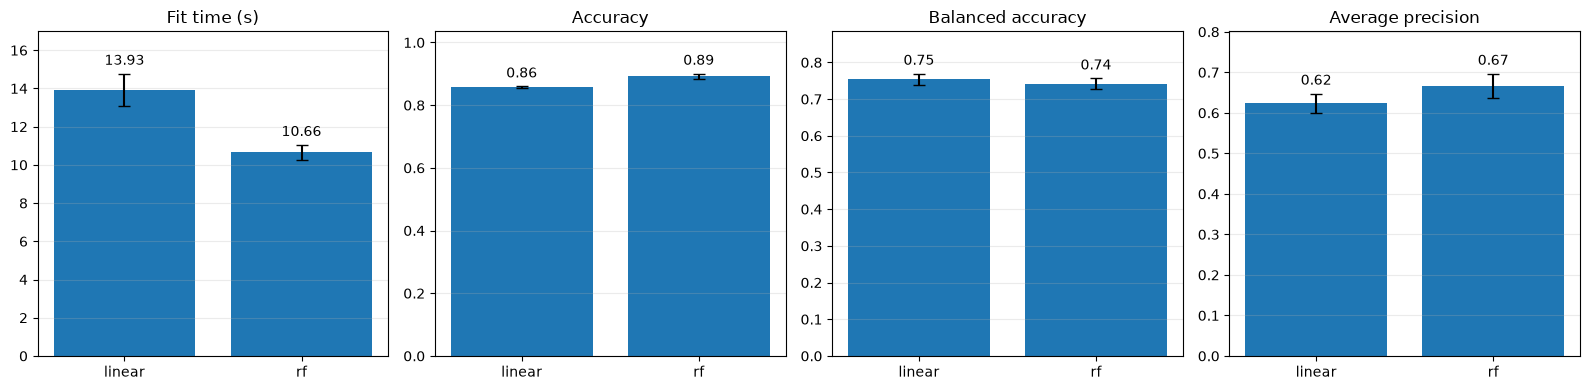

In [5]:
plot_metrics = [
    ("fit_seconds", "Fit time (s)"),
    ("accuracy", "Accuracy"),
    ("balanced_accuracy", "Balanced accuracy"),
    ("average_precision", "Average precision"),
]
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(16, 4))
for axis, (metric, label) in zip(axes, plot_metrics):
    grouped = results_df.groupby("estimator")[metric]
    means = grouped.mean().reindex(ESTIMATORS.keys())
    errors = grouped.std().reindex(ESTIMATORS.keys()).fillna(0)
    bars = axis.bar(means.index, means.values, yerr=errors.values, capsize=4)
    for bar, mean, error in zip(bars, means.values, errors.values):
        axis.annotate(
            f"{mean:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, mean + error),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )
    axis.set_ylim(top=max(means.values + errors.values) * 1.15)
    axis.set_title(label)
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Interpretation notes

- `fit_seconds` includes NSPPK feature extraction for the training graphs plus estimator fitting.
- `predict_seconds` measures the wrapper's `predict()` call, including test graph transformation.
- `score_seconds` separately measures `predict_proba()`, also including a test graph transformation.
- Runtime varies with CPU load, multiprocessing behavior, and scikit-learn version. Keep the dataset limit, split seeds, and estimator parameters fixed when comparing runs.
